# 01. Постановка задачи и базовые модели

**Задача:** по описанию вакансии предсказать месячную зарплату в сомах.
Тип задачи: **регрессия**.

**Зачем:** 52% вакансий скрывают зарплату (см. анализ в `kg-job-market-analysis`). Модель, обученная
на вакансиях с зарплатой, может оценить скрытые зарплаты и показать соискателю ожидаемый уровень оплаты.

**Данные:** `data/vacancies_clean.csv` из ноутбука `02_cleaning` аналитического проекта.

## Решения по постановке

| Решение | Почему |
|---|---|
| Целевая переменная: **log(зарплаты)** | распределение зарплат сильно скошено (асимметрия 4,3 → 0,5 после логарифма, гипотеза H5) |
| Метрика: **MAE в сомах** | понятна без подготовки: «в среднем модель ошибается на X сом» |
| Дополнительно: медианная ошибка, MAPE, доля ошибок < 20%, R² | MAE чувствительна к редким дорогим вакансиям; другие метрики дают полную картину |
| Только признаки, которые есть и у вакансий **без** зарплаты | иначе модель нельзя применить к скрытым зарплатам (утечка данных) |
| Разбиение с учётом **почти одинаковых объявлений** | повторно опубликованная вакансия не должна попасть и в обучение, и в тест |
| Из текста удалены **числа и названия валют** | объявления с указанной зарплатой часто повторяют её в тексте, а объявления со скрытой нет: иначе модель «читает ответ» из текста |
| Убраны 20 объявлений lalafo с зарплатой в 5+ раз выше или ниже медианы профессии | шум в разметке: «швея за 500 000», продажа бизнеса, комиссия такси вместо зарплаты |

In [1]:
import sys
sys.path.insert(0, "../src")
import prep

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

df = prep.load()
data = prep.labeled(df, verbose=True)
hid = prep.hidden(df)
print(f"Всего вакансий: {len(df)} | с зарплатой (обучение и тест): {len(data)} | "
      f"со скрытой зарплатой (для предсказания): {len(hid)}")

Убрано как шум в разметке (lalafo, зарплата в 5+ раз от медианы профессии): 20
Всего вакансий: 12646 | с зарплатой (обучение и тест): 5820 | со скрытой зарплатой (для предсказания): 6516


## 1. Признаки

Колонки, которые есть **только при указанной зарплате**, исключены: исходные суммы, валюта,
формат зарплаты, период оплаты, отметка выброса. Если бы модель училась на них, она
не смогла бы работать со скрытыми зарплатами, а оценка качества была бы завышена.

In [2]:
features = pd.DataFrame({
    "признак": prep.CAT_FEATURES + prep.NUM_FEATURES + prep.BOOL_FEATURES,
    "тип": ["категориальный"] * len(prep.CAT_FEATURES) + ["числовой"] * len(prep.NUM_FEATURES)
           + ["да/нет"] * len(prep.BOOL_FEATURES),
    "уникальных значений": [data[c].nunique() for c in prep.CAT_FEATURES + prep.NUM_FEATURES + prep.BOOL_FEATURES],
})
print("Исключены (утечка):", ", ".join(prep.LEAKY))
features

Исключены (утечка): compensation_from, compensation_to, compensation_currency, salary_type, pay_period, salary_outlier, salary_hidden, has_salary


,признак,тип,уникальных значений
0,category,категориальный,27
1,sub_category,категориальный,153
2,city,категориальный,3
3,source,категориальный,2
4,education,категориальный,3
5,gender_req,категориальный,4
6,schedule,категориальный,25
7,experience_start,числовой,4
8,n_skills,числовой,16
9,text_len,числовой,829


## 2. Разбиение на обучение и тест

- 80% обучение, 20% тест.
- Объявления с одинаковым названием и одинаковым началом текста объединены в группу
  и целиком попадают либо в обучение, либо в тест. Это защищает от «запоминания»
  повторно опубликованных вакансий.
- Тестовая выборка не используется ни для обучения, ни для выбора модели.

In [3]:
train, test = prep.split(data)
print(f"Обучение: {len(train)} | тест: {len(test)}")
print(f"Общих групп между обучением и тестом: {len(set(train.dup_group) & set(test.dup_group))}")
print(f"Медиана зарплаты: обучение {np.exp(train.y).median():,.0f}, тест {np.exp(test.y).median():,.0f}")

Обучение: 4655 | тест: 1165
Общих групп между обучением и тестом: 0
Медиана зарплаты: обучение 39,000, тест 40,000


## 3. Базовые модели

Базовые модели показывают, от какого уровня считать качество. Любая сложная модель
должна быть лучше них, иначе она не нужна.

1. **Медиана рынка:** всем вакансиям одна и та же зарплата.
2. **Медиана профессии:** медиана по `sub_category` из обучающей выборки
   (если профессии нет в обучении, берётся медиана сферы). Так поступил бы человек без ML.
3. **Ridge-регрессия:** линейная модель на one-hot признаках.
   Регуляризация (alpha) не даёт модели переобучиться на редких профессиях.

In [4]:
results = {}

# 1. медиана рынка
p1 = np.full(len(test), train.y.median())
results["медиана рынка"] = prep.metrics(test.y.values, p1)

# 2. медиана профессии
by_prof = train.groupby("sub_category").y.median()
by_cat = train.groupby("category").y.median()
p2 = test.sub_category.map(by_prof).fillna(test.category.map(by_cat)).fillna(train.y.median())
results["медиана профессии"] = prep.metrics(test.y.values, p2.values)

# 3. Ridge
X_cols = prep.CAT_FEATURES + prep.NUM_FEATURES + prep.BOOL_FEATURES
ridge = make_pipeline(
    ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), prep.CAT_FEATURES),
        ("num", StandardScaler(), prep.NUM_FEATURES + prep.BOOL_FEATURES),
    ]),
    Ridge(alpha=3),
)
ridge.fit(train[X_cols], train.y)
p3 = ridge.predict(test[X_cols])
results["Ridge"] = prep.metrics(test.y.values, p3)

res = pd.DataFrame(results).T
res.style.format({"MAE, сом": "{:,.0f}", "медианная ошибка, сом": "{:,.0f}", "MAPE, %": "{:.1f}",
                  "доля ошибок < 20%": "{:.0%}", "R² (log)": "{:.3f}"})

,"MAE, сом","медианная ошибка, сом","MAPE, %",доля ошибок < 20%,R² (log)
медиана рынка,"20,417","13,000",44.9,25%,-0.004
медиана профессии,"17,793","10,000",38.0,38%,0.213
Ridge,"17,512","10,561",38.1,38%,0.258


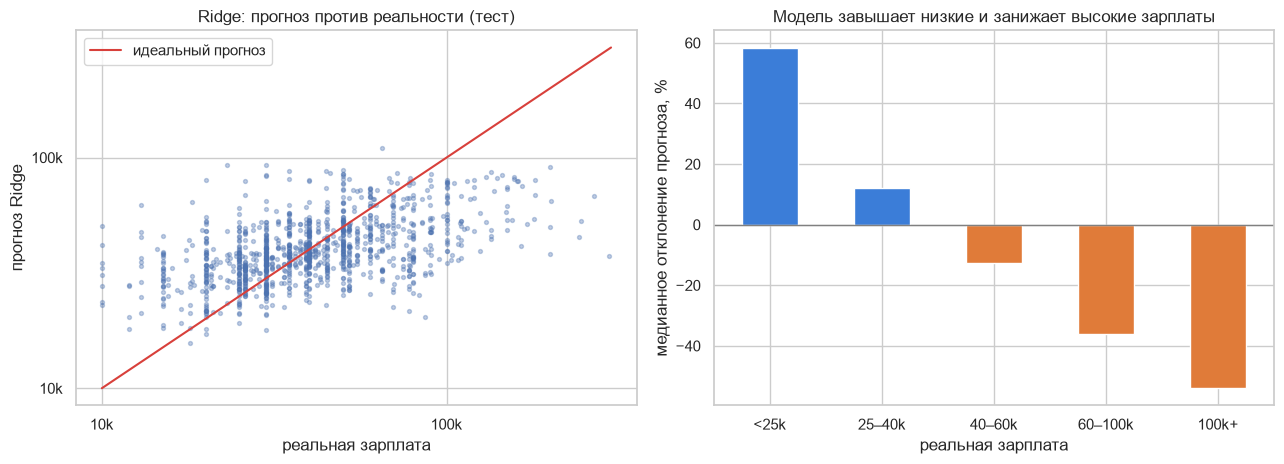

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
yt, yp = np.exp(test.y), np.exp(p3)
ax[0].scatter(yt, yp, s=8, alpha=.35)
lim = [10_000, 300_000]
ax[0].plot(lim, lim, color="#d8403b", lw=1.5, label="идеальный прогноз")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].xaxis.set_major_formatter(K); ax[0].yaxis.set_major_formatter(K)
ax[0].set_xlabel("реальная зарплата"); ax[0].set_ylabel("прогноз Ridge"); ax[0].legend()
ax[0].set_title("Ridge: прогноз против реальности (тест)")

bins = pd.cut(yt, [0, 25_000, 40_000, 60_000, 100_000, 1e7], labels=["<25k", "25–40k", "40–60k", "60–100k", "100k+"])
err = pd.DataFrame({"bin": bins, "bias": (yp - yt) / yt * 100}).groupby("bin", observed=True)["bias"].median()
err.plot(kind="bar", ax=ax[1], color=np.where(err > 0, "#3b7dd8", "#e07b39"))
ax[1].axhline(0, color="grey", lw=1); ax[1].set_xlabel("реальная зарплата")
ax[1].set_ylabel("медианное отклонение прогноза, %")
ax[1].set_title("Модель завышает низкие и занижает высокие зарплаты")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG + "01_baseline.png", dpi=150); plt.show()

## Выводы

- **Медиана рынка** ошибается в среднем примерно на 20 400 сом: это нижняя планка.
- **Медиана профессии** сразу снижает ошибку примерно до 17 800 сом: профессия объясняет
  заметную часть различий в зарплате.
- **Ridge** на структурированных признаках почти не лучше медианы профессии (≈ 17 500 сом).
  Значит, сфера, опыт, город и источник добавляют к профессии немного информации.
- Как у любой модели «к среднему», прогнозы **сжаты к центру**: низкие зарплаты завышаются,
  высокие занижаются.

**Что дальше (ноутбук 02):** сравнение с нелинейными моделями (Random Forest, LightGBM, CatBoost)
и с моделями, которые читают **текст объявления**: в тексте есть информация, которой нет
в структурированных полях (уровень должности, условия, конкретные навыки).